# TP1 — Análisis exploratorio: tweets sobre desastres naturales

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juanbalella20/TP1---1-Ciencia-de-Datos-Catedra-Martinelli/blob/dev/Trabajo-PracticoN%C2%B01/twitter.ipynb)

El dataset reúne **7613 tweets** que contienen palabras asociadas a desastres (*fire*, *flood*, *explosion*, etc.). Cada tweet tiene las columnas:

- **id**: identificador del tweet.
- **keyword**: palabra de desastre asociada al tweet (puede faltar).
- **location**: ubicación escrita por el usuario (puede faltar).
- **text**: texto del tweet.
- **target**: **1** si el tweet describe una **emergencia real**, **0** si usa la palabra en **sentido figurado** ("this song is fire").

**Objetivo:** encontrar qué características de un tweet ayudan a distinguir una emergencia real del lenguaje figurado.

El trabajo se divide en tres partes: consultas con **Pandas**, consultas con **Spark** (usando solo RDDs) y las **conclusiones principales**. Cada consulta plantea una hipótesis, la resuelve y cierra con una conclusión.

> Para ejecutarlo en Colab: si el archivo `train.csv` no está en el entorno, la primera celda pide subirlo.

In [1]:
import os
import re

import matplotlib.pyplot as plt
import pandas as pd

# en Colab el CSV no viene junto con el notebook: si falta, se pide subirlo
if not os.path.exists("train.csv"):
    from google.colab import files
    files.upload()

data_frame = pd.read_csv("train.csv")
data_frame

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1
...,...,...,...,...,...
7608,10869,NaN,NaN,Two giant cranes holding a bridge collapse int...,1
7609,10870,NaN,NaN,@aria_ahrary @TheTawniest The out of control w...,1
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1
7611,10872,NaN,NaN,Police investigating after an e-bike collided ...,1


Como referencia para todas las consultas: en el dataset completo, el **43,0%** de los tweets son emergencias reales y el **57,0%** es lenguaje figurado. Una característica aporta información si, al separar los tweets según ella, los porcentajes se alejan de estos valores.

In [2]:
proporcion_global_real = data_frame["target"].mean() * 100
proporcion_global_real

np.float64(42.96597924602653)

# Pandas

## Consulta Pandas 1: características del texto y tipo de tweet

**Hipótesis:** algunas características del texto marcan el tono del tweet:

- Los tweets en **primera persona** (*I*, *I'm*, *my*, *me*) tienden a ser **lenguaje figurado**: quien habla de sí mismo suele contar una experiencia personal o exagerar ("I'm dying", "my life is a disaster").
- Los tweets con **menciones (@)** tienden a ser **lenguaje figurado**: la mención suele dirigirse a un amigo, en un tono informal.
- Los tweets con **URL** tienden a ser **emergencias reales**: el enlace suele adjuntar una noticia sobre el hecho.

Para comprobarlo, marcamos cada característica en una columna booleana y, para cada una, comparamos el porcentaje de emergencias reales entre los tweets que la tienen y los que no.

In [3]:
texto = data_frame["text"]

# \b marca límite de palabra: evita que "me" coincida dentro de "meeting"
caracteristicas_texto = pd.DataFrame({
    "Primera persona": texto.str.contains(r"\b(?:i|i'm|im|my|me)\b", case=False, regex=True),
    "Mención @": texto.str.contains("@", regex=False),
    "URL": texto.str.contains(r"https?://", regex=True),
})

# formato largo: una fila por (tweet, característica) para agrupar todas juntas
resumen_texto = (
    caracteristicas_texto.assign(target=data_frame["target"])
    .melt(id_vars="target", var_name="caracteristica", value_name="tiene")
    .groupby(["caracteristica", "tiene"])["target"]
    .agg(cantidad_tweets="size", emergencia_real="mean")
)
resumen_texto["emergencia_real"] = resumen_texto["emergencia_real"] * 100
resumen_texto["lenguaje_figurado"] = 100 - resumen_texto["emergencia_real"]

resumen_texto.round(1)

cantidad_tweets  emergencia_real  lenguaje_figurado
caracteristica  tiene                                                     
Mención @       False             5574             46.6               53.4
                True              2039             33.2               66.8
Primera persona False             5788             49.4               50.6
                True              1825             22.6               77.4
URL             False             3642             30.2               69.8
                True              3971             54.7               45.3

### Visualización: porcentaje de emergencias reales según cada característica

Un **gráfico de barras agrupadas** permite comparar, para cada característica, el grupo que la tiene contra el que no. La línea punteada marca el porcentaje de emergencias reales en todo el dataset: cuanto más se aleja una barra de esa línea, más información aporta la característica.

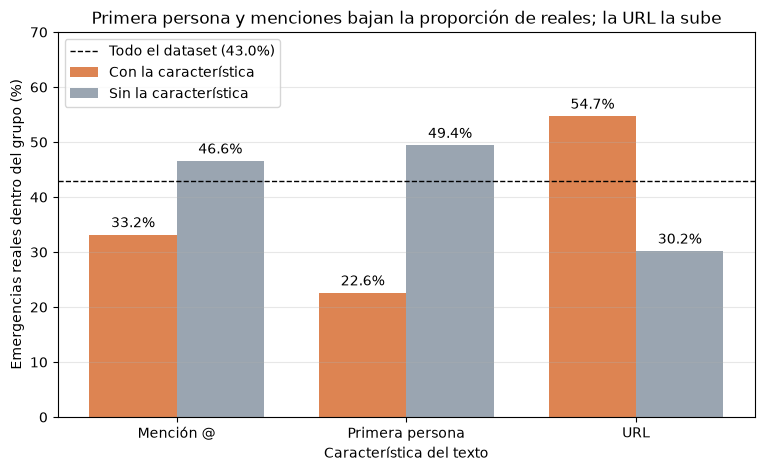

In [4]:
emergencia_por_grupo = resumen_texto["emergencia_real"].unstack()  # filas: característica, columnas: tiene
nombres = emergencia_por_grupo.index
posiciones = range(len(nombres))
ancho = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
barras_con = ax.bar([p - ancho / 2 for p in posiciones], emergencia_por_grupo[True], ancho,
                    color="#DD8452", label="Con la característica")
barras_sin = ax.bar([p + ancho / 2 for p in posiciones], emergencia_por_grupo[False], ancho,
                    color="#9AA5B1", label="Sin la característica")
ax.bar_label(barras_con, fmt="%.1f%%", padding=3)
ax.bar_label(barras_sin, fmt="%.1f%%", padding=3)
ax.axhline(proporcion_global_real, color="black", linestyle="--", linewidth=1,
           label=f"Todo el dataset ({proporcion_global_real:.1f}%)")

ax.set_xticks(list(posiciones), nombres)
ax.set_xlabel("Característica del texto")
ax.set_ylabel("Emergencias reales dentro del grupo (%)")
ax.set_ylim(0, 70)
ax.set_title("Primera persona y menciones bajan la proporción de reales; la URL la sube")
ax.legend(loc="upper left")
ax.grid(axis="y", alpha=0.3)

plt.show()

**Conclusión:** las tres hipótesis se confirman, con distinta fuerza.

- **Primera persona:** es la señal más fuerte. Solo el **22,6%** de los tweets en primera persona son emergencias reales, contra el **49,4%** de los que no la usan.
- **URL:** entre los tweets con enlace, el **54,7%** son emergencias reales, contra el **30,2%** de los que no tienen. La diferencia entre grupos es grande (24 puntos), aunque los tweets con URL apenas superan la mitad.
- **Mención @:** el **33,2%** de los tweets con mención son reales, contra el **46,6%** de los que no tienen. Las menciones se asocian con el lenguaje figurado, pero de forma moderada: 2 de cada 3 tweets con **@** son figurados, frente al 57% de todo el dataset.

Ninguna característica alcanza por sí sola para clasificar un tweet, pero las tres separan los grupos en la dirección esperada.

## Consulta Pandas 2: largo del tweet

**Hipótesis:** los tweets de **emergencia real** (**target** = 1) son, en promedio, **más largos** que los de **lenguaje figurado** (**target** = 0).

La idea es que, al informar una emergencia real, el autor necesita incluir datos concretos (el lugar, el tipo de incidente, las consecuencias), lo que genera un texto más extenso. En cambio, en el lenguaje figurado alcanza con una palabra de desastre usada como adjetivo o para enfatizar una situación.

Para comprobarlo, calculamos el largo de cada tweet en caracteres y comparamos sus estadísticas descriptivas según el **target**. Además, medimos la correlación entre el largo y el **target**.

In [5]:
data_frame["largo_tweet"] = data_frame["text"].str.len()
largo_por_target = data_frame.groupby("target")["largo_tweet"].describe()
largo_por_target

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,4342.0,95.706817,35.885924,7.0,68.0,101.0,130.0,157.0
1,3271.0,108.113421,29.309854,14.0,88.0,115.0,136.0,151.0


In [6]:
data_frame[["target", "largo_tweet"]].corr()

,target,largo_tweet
target,1.000000,0.181817
largo_tweet,0.181817,1.000000


**Conclusión:** la hipótesis se confirma en la dirección esperada, pero no en magnitud.

- **Promedio:** los tweets de emergencia real tienen en promedio **108,1** caracteres, contra **95,7** de los de lenguaje figurado. Es decir, son algo más largos.
- **Dispersión:** los desvíos estándar son de **29,3** (emergencia real) y **35,9** (lenguaje figurado). Ambos son mucho más grandes que la diferencia entre los promedios (unos 12 caracteres), por lo que dentro de cada grupo hay tweets de todos los largos.
- **Cuartiles:** el 50% central de los tweets de emergencia real mide entre **88** y **136** caracteres, un rango que cae casi entero dentro del **68-130** del lenguaje figurado. Los dos grupos se superponen en gran medida.
- **Correlación:** la correlación entre el largo y el **target** es de **0,18**, lo que indica una relación débil. Elevada al cuadrado, significa que el largo explica solo alrededor del **3%** de la variación en el tipo de tweet.

En resumen, el largo del tweet es una señal real pero secundaria: conocer cuánto mide un tweet casi no ayuda a saber si es real o figurado. Para distinguir los dos grupos hay que analizar **qué** dice el tweet, no **cuánto** mide.

### Visualización: distribución del largo según el tipo de tweet

Un **boxplot** muestra en una sola figura la mediana (línea negra), el 50% central de los datos (la caja, del cuartil 1 al 3) y el rango total (los bigotes). Es el gráfico adecuado para comparar distribuciones y ver si se superponen, que es justamente lo que analizamos en esta consulta.

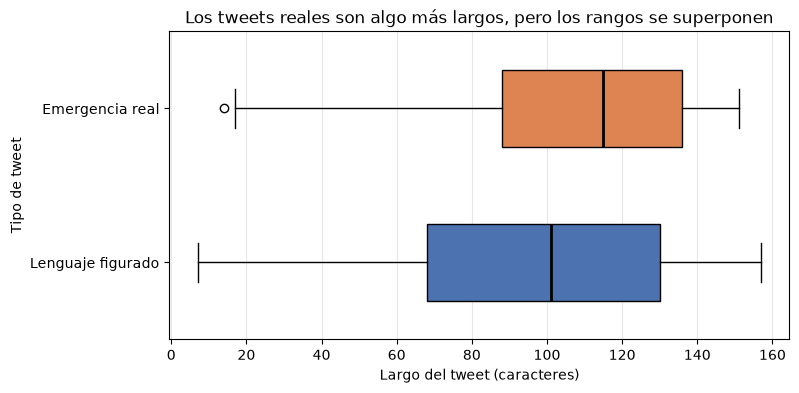

In [7]:
largos = [
    data_frame.loc[data_frame["target"] == 0, "largo_tweet"],
    data_frame.loc[data_frame["target"] == 1, "largo_tweet"],
]

fig, ax = plt.subplots(figsize=(8, 4))
cajas = ax.boxplot(largos, orientation="horizontal", patch_artist=True, widths=0.5,
                   medianprops={"color": "black", "linewidth": 2})
for caja, color in zip(cajas["boxes"], ["#4C72B0", "#DD8452"]):
    caja.set_facecolor(color)

ax.set_yticks([1, 2], ["Lenguaje figurado", "Emergencia real"])
ax.set_xlabel("Largo del tweet (caracteres)")
ax.set_ylabel("Tipo de tweet")
ax.set_title("Los tweets reales son algo más largos, pero los rangos se superponen")
ax.grid(axis="x", alpha=0.3)

plt.show()

La caja de emergencia real está corrida hacia la derecha (tweets más largos), pero se superpone casi por completo con la de lenguaje figurado. Esto confirma visualmente la conclusión: el largo es una señal real pero débil.

## Consulta Pandas 3: keywords y tipo de tweet

Queremos ver si la **keyword** de un tweet se relaciona con su **target**, es decir, si hay palabras clave que aparecen casi siempre en emergencias reales y otras que aparecen casi siempre en lenguaje figurado.

In [8]:
data_frame["keyword"].nunique()

221

Al ejecutar la consulta vemos que la columna **keyword** tiene **221** valores distintos (sin contar los tweets que no tienen keyword).

**Hipótesis:** algunas keywords de desastre se usan mayormente en sentido figurado. Por ejemplo, **accident** puede referirse a un error cotidiano ("it was an **accident**") y no a una emergencia real, sino a una equivocación humana.

Para comprobarlo, calculamos el **ratio de emergencia real por keyword**: el promedio del **target** para cada keyword. Como el **target** vale 0 o 1, ese promedio es directamente la proporción de tweets de emergencia real. Un valor cercano a 1 indica que la keyword se usa casi siempre en emergencias reales, y uno cercano a 0, que se usa casi siempre en sentido figurado.

In [9]:
ratio_por_keyword = data_frame.groupby("keyword")["target"].agg(["mean", "count"])
ratio_por_keyword.nlargest(7, "mean")

,mean,count
keyword,,
debris,1.000000,37
derailment,1.000000,39
wreckage,1.000000,39
outbreak,0.975000,40
oil%20spill,0.973684,38
typhoon,0.973684,38
suicide%20bombing,0.969697,33


**Resultado (keywords más asociadas a emergencias reales):** *debris*, *derailment* y *wreckage* tienen un ratio de **1**, es decir, el **100%** de sus tweets son emergencias reales. Les siguen *outbreak*, *oil spill*, *typhoon* y *suicide bombing*, todas por encima del **96%**.

Son palabras que describen hechos concretos y específicos (escombros, descarrilamientos, derrames de petróleo, tifones), que difícilmente se usan en sentido figurado. Cuando un tweet contiene alguna de estas keywords, casi con seguridad habla de una emergencia real.

In [10]:
ratio_por_keyword.nsmallest(7, "mean")

,mean,count
keyword,,
aftershock,0.000000,34
body%20bags,0.024390,41
ruin,0.027027,37
blazing,0.029412,34
body%20bag,0.030303,33
electrocute,0.031250,32
screaming,0.055556,36


**Resultado (keywords más asociadas al lenguaje figurado):** *aftershock* tiene un ratio de **0**, es decir, ninguno de sus tweets es una emergencia real. Le siguen *body bags*, *ruin*, *blazing*, *body bag* y *electrocute*, todas por debajo del **4%**, y *screaming*, con menos del **6%**.

Son palabras que, aunque suenan a desastre, se usan mayormente para exagerar o expresar emociones ("this ruined my day", "I'm screaming"). Cuando un tweet contiene alguna de estas keywords, casi con seguridad usa lenguaje figurado.

Por último, buscamos las keywords **ambiguas**: aquellas que no permiten distinguir entre emergencia real y lenguaje figurado porque se usan en ambos sentidos por igual.

Para encontrarlas, calculamos qué tan lejos está el ratio de cada keyword del **0,5** (la mitad exacta) y nos quedamos con las más cercanas. Solo consideramos keywords con al menos 20 tweets, para que el ratio no dependa de unos pocos casos.

In [11]:
ratio_por_keyword["distancia_a_0.5"] = (ratio_por_keyword["mean"] - 0.5).abs()

# solo keywords con al menos 20 apariciones, para que el ratio no dependa de pocos casos
keywords_frecuentes = ratio_por_keyword[ratio_por_keyword["count"] >= 20]

keywords_ambiguas = keywords_frecuentes.nsmallest(10, "distancia_a_0.5")
keywords_ambiguas

,mean,count,distancia_a_0.5
keyword,,,
bombed,0.500000,38,0.000000
explosion,0.512821,39,0.012821
hail,0.514286,35,0.014286
storm,0.514286,35,0.014286
derail,0.485714,35,0.014286
rescued,0.485714,35,0.014286
hijack,0.484848,33,0.015152
lightning,0.515152,33,0.015152
hostage,0.483871,31,0.016129


**Conclusión:** cuanto más cerca del **0,5** está el ratio de una keyword, más ambigua es, porque se reparte por igual entre emergencias reales y lenguaje figurado. Por eso ordenamos por la distancia a ese valor.

- **bombed** es totalmente ambigua: su ratio es exactamente **0,5**, por lo que no se inclina hacia ninguno de los dos tipos de tweet.
- **explosion** sigue un camino muy parecido, con un ratio apenas por encima de 0,5.

Estas keywords, por sí solas, no aportan información para saber si un tweet describe una emergencia real o usa lenguaje figurado.

## Consulta Pandas 4: vocabulario de cada tipo de tweet

**Hipótesis:** más allá de la keyword, el vocabulario del texto es distinto entre los dos tipos de tweet: los reales usan palabras de hechos concretos y los figurados, palabras de la conversación cotidiana.

Para comprobarlo, separamos el texto de cada tweet en palabras y contamos cuántas veces aparece cada palabra en cada tipo de tweet.

Al hacer un primer conteo, las palabras más repetidas son casi todas **stopwords**: preposiciones, artículos, pronombres, conjunciones y verbos auxiliares, que aparecen en cualquier texto en inglés sin importar el tema. Por eso las filtramos, junto con los enlaces, las menciones y las palabras de menos de 3 letras. La función `tokenizar` se reutiliza después en las consultas de Spark, para que ambas partes cuenten las palabras de la misma forma.

In [12]:
stopwords = set("""
a about above after again against all also am an and any are aren't as at be because been before
being below between both but by can can't cannot could couldn't did didn't do does doesn't doing
don't down during each few first for from further get got had hadn't has hasn't have haven't having
he he's her here here's hers herself him himself his how how's i i'd i'll i'm i've if in into is
isn't it it's its itself just let's like me more most much my myself new no nor not now of off on
once one only or other our ours ourselves out over own same say says she she's should shouldn't so
some such than that that's the their theirs them themselves then there there's these they they'd
they'll they're they've this those through to too two under until up us very via was wasn't we
we'd we'll we're we've were weren't what what's when when's where where's which while who who's
whom why why's will with won't would wouldn't you you'd you'll you're you've your yours yourself
yourselves amp im dont cant rt gt lt
""".split())


def tokenizar(texto):
    # saca enlaces y menciones, y deja solo palabras formadas por letras
    texto = re.sub(r"https?://\S+|@\w+", " ", texto.lower()).replace("&amp;", "&")
    return [palabra for palabra in re.findall(r"[a-z]+(?:'[a-z]+)?", texto)
            if len(palabra) > 2 and palabra not in stopwords]


palabras = (
    data_frame.assign(palabra=data_frame["text"].map(tokenizar))
    .explode("palabra")
    .dropna(subset=["palabra"])
)
frecuencias = palabras.groupby(["palabra", "target"]).size().unstack(fill_value=0)
frecuencias.columns = ["figurado", "real"]

pd.DataFrame({
    "Más frecuentes en emergencia real": frecuencias["real"].nlargest(15).index,
    "Más frecuentes en lenguaje figurado": frecuencias["figurado"].nlargest(15).index,
})

,Más frecuentes en emergencia real,Más frecuentes en lenguaje figurado
0,fire,body
1,news,video
2,disaster,people
3,suicide,love
4,california,day
5,police,know
6,people,time
7,killed,back
8,hiroshima,full
9,storm,see


**Conclusión:** la hipótesis se confirma.

- En los tweets de **emergencia real** dominan palabras ligadas a hechos concretos y sus consecuencias: *fire*, *news*, *disaster*, *suicide*, *police*, *killed*, *storm* o *crash*, además de lugares como *california* o *hiroshima*.
- En los tweets de **lenguaje figurado** aparecen palabras de la conversación cotidiana: *love*, *day*, *know*, *time*, *back* o *going*.

Algunas palabras aparecen en los dos rankings (*people*, *emergency*, *fire*), lo que muestra que el vocabulario de desastre también se usa en sentido figurado. La visualización siguiente compara cuántas veces aparece cada palabra en cada grupo.

### Visualización: vocabulario de cada tipo de tweet

En un **gráfico de dispersión**, cada punto es una de las 25 palabras más frecuentes del dataset (sumando los dos tipos). Su posición indica cuántas veces aparece en tweets de emergencia real (eje horizontal) y en tweets de lenguaje figurado (eje vertical). La línea punteada marca las palabras que aparecen lo mismo en ambos grupos: cuanto más lejos de ella está un punto, más característica es la palabra de un solo tipo de tweet.

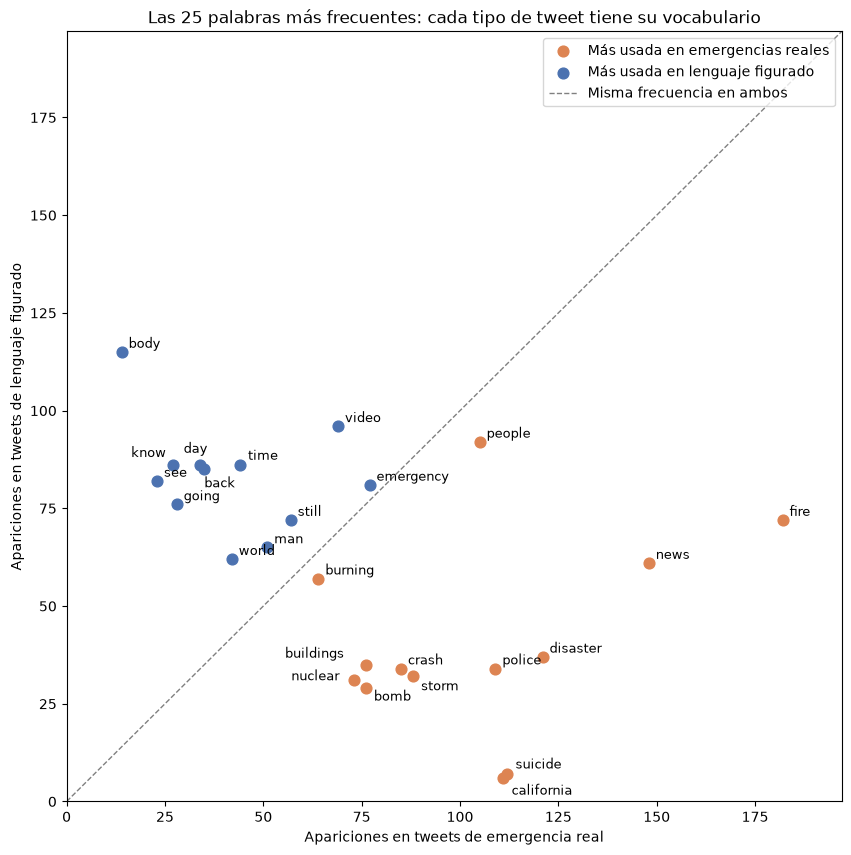

In [13]:
top_palabras = frecuencias.assign(total=frecuencias.sum(axis=1)).nlargest(25, "total")
es_real = top_palabras["real"] > top_palabras["figurado"]

fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(top_palabras.loc[es_real, "real"], top_palabras.loc[es_real, "figurado"],
           color="#DD8452", s=60, label="Más usada en emergencias reales")
ax.scatter(top_palabras.loc[~es_real, "real"], top_palabras.loc[~es_real, "figurado"],
           color="#4C72B0", s=60, label="Más usada en lenguaje figurado")

limite = top_palabras[["real", "figurado"]].max().max() + 15
ax.plot([0, limite], [0, limite], color="gray", linestyle="--", linewidth=1, label="Misma frecuencia en ambos")

# desplazamientos a mano para las palabras cuyos puntos quedan casi encimados
desplazamientos = {"know": (-30, 6), "day": (-12, 9), "back": (0, -13), "time": (6, 4),
                   "buildings": (-58, 5), "storm": (6, -10), "nuclear": (-45, 0), "bomb": (6, -9),
                   "suicide": (6, 4), "california": (6, -12)}
for palabra, fila in top_palabras.iterrows():
    ax.annotate(palabra, (fila["real"], fila["figurado"]), xytext=desplazamientos.get(palabra, (5, 3)),
                textcoords="offset points", fontsize=9)

ax.set_xlim(0, limite)
ax.set_ylim(0, limite)
ax.set_xlabel("Apariciones en tweets de emergencia real")
ax.set_ylabel("Apariciones en tweets de lenguaje figurado")
ax.set_title("Las 25 palabras más frecuentes: cada tipo de tweet tiene su vocabulario")
ax.legend(loc="upper right")

plt.show()

Las palabras se separan a cada lado de la diagonal. Debajo quedan las de emergencia real (*fire*, *news*, *disaster*, *police*, *suicide*, *california*) y arriba las de lenguaje figurado (*body*, *video*, *time*, *day*, *know*, *see*). Unas pocas, como *people*, *emergency*, *burning* o *still*, quedan cerca de la línea y se usan en ambos sentidos.

## Consulta Pandas 5: largo del tweet dentro de cada keyword

En la consulta 2 vimos que los tweets reales son, en promedio, unos 12 caracteres más largos. Pero esa diferencia podría deberse a la keyword y no al tipo de tweet: si las keywords que se usan sobre todo en emergencias reales generan textos más largos (por ejemplo, porque se tuitean como titulares de noticias), el promedio general de los reales sube aunque, para una misma keyword, real y figurado midan lo mismo.

**Hipótesis:** la diferencia de largo se mantiene **dentro de cada keyword**: para una misma keyword, los tweets reales siguen siendo más largos que los figurados.

Para comprobarlo, armamos una tabla dinámica con una fila por keyword y el largo promedio de sus tweets reales y figurados. Solo consideramos keywords con al menos 5 tweets de cada tipo, para que los promedios no dependan de uno o dos casos.

In [14]:
largo_por_keyword = data_frame.pivot_table(
    index="keyword", columns="target", values="largo_tweet", aggfunc=["mean", "count"]
)
largo_por_keyword.columns = ["largo_figurado", "largo_real", "tweets_figurado", "tweets_real"]

largo_por_keyword = largo_por_keyword[
    (largo_por_keyword["tweets_figurado"] >= 5) & (largo_por_keyword["tweets_real"] >= 5)
].copy()
largo_por_keyword["diferencia"] = largo_por_keyword["largo_real"] - largo_por_keyword["largo_figurado"]

largo_por_keyword["diferencia"].describe()

count    171.000000
mean       6.690989
std       15.872213
min      -29.781046
25%       -5.310363
50%        7.035714
75%       19.272436
max       47.100000
Name: diferencia, dtype: float64

In [15]:
# porcentaje de keywords en las que el tweet real promedio es más largo que el figurado
(largo_por_keyword["diferencia"] > 0).mean() * 100

np.float64(65.49707602339181)

In [16]:
pd.concat({
    "Reales mucho más largos": largo_por_keyword.nlargest(5, "diferencia"),
    "Figurados más largos": largo_por_keyword.nsmallest(5, "diferencia"),
}).round(1)

largo_figurado  largo_real  \
                        keyword                                  
Reales mucho más largos screams               63.7       110.8   
                        devastated            78.5       122.1   
                        fatal                 69.8       112.7   
                        curfew                81.2       120.0   
                        injured               81.5       117.9   
Figurados más largos    derail               125.7        95.9   
                        wreck                 93.9        65.6   
                        injury               109.3        83.6   
                        riot                 111.9        89.0   
                        explosion            120.2        97.7   

                                    tweets_figurado  tweets_real  diferencia  
                        keyword                                               
Reales mucho más largos screams                30.0          5.0        47.1  
                        devastated             13.0         18.0        43.6  
                        fatal                  12.0         26.0        43.0  
                        curfew                 32.0          5.0        38.8  
                        injured                11.0         24.0        36.3  
Figurados más largos    derail                 18.0         17.0       -29.8  
                        wreck                  30.0          7.0       -28.3  
                        injury                 27.0         11.0       -25.7  
                        riot                   28.0          6.0       -22.9  
                        explosion              19.0         20.0       -22.5

**Conclusión:** la hipótesis se confirma solo en parte.

- De las **171** keywords con suficientes tweets de los dos tipos, en el **65,5%** el tweet real promedio es más largo que el figurado. La diferencia mediana dentro de cada keyword es de **7** caracteres, algo menor que los 12 de la diferencia general: parte de la diferencia de la consulta 2 se explica por la keyword.
- La dispersión es enorme (desvío de **15,9** caracteres): en keywords como *screams*, *devastated* o *fatal* los tweets reales son más de **40** caracteres más largos, pero en *derail*, *wreck*, *injury* o *explosion* pasa lo contrario y los figurados son los más largos.

Es decir, el largo no es una señal estable: su efecto depende de la keyword. Esto refuerza la conclusión de la consulta 2: hay que mirar **qué** dice el tweet más que **cuánto** mide.

## Consulta Pandas 6: la columna location

Queda una columna sin analizar: **location**, que el usuario completa libremente y que muchas veces está vacía.

**Hipótesis:** quien informa una emergencia real completa su ubicación con más frecuencia, por lo que el porcentaje de tweets **sin** ubicación debería ser menor entre los de emergencia real que entre los de lenguaje figurado.

Para comprobarlo, armamos un perfil de la columna **location** para cada tipo de tweet: el porcentaje de tweets sin ubicación, cuántas ubicaciones distintas aparecen y cuál es la más frecuente.

In [17]:
perfil_location = data_frame.groupby("target")["location"].agg(
    cantidad_tweets="size",
    sin_location_pct=lambda ubicaciones: ubicaciones.isna().mean() * 100,
    ubicaciones_distintas="nunique",
    mas_frecuente=lambda ubicaciones: ubicaciones.value_counts().index[0],
)
perfil_location.index = perfil_location.index.map({0: "Lenguaje figurado", 1: "Emergencia real"})
perfil_location.round(1)

,cantidad_tweets,sin_location_pct,ubicaciones_distintas,mas_frecuente
target,,,,
Lenguaje figurado,4342,33.6,2142,New York
Emergencia real,3271,32.9,1513,USA


Para verlo también desde el otro lado, comparamos el tipo de tweet entre los que tienen ubicación y los que no, junto con el total del dataset (fila **All**).

In [18]:
tiene_location = data_frame["location"].notna().map({True: "Con location", False: "Sin location"})
(pd.crosstab(tiene_location, data_frame["target"], normalize="index", margins=True) * 100).round(1)

target,0,1
location,,
Con location,56.8,43.2
Sin location,57.6,42.4
All,57.0,43.0


**Conclusión:** la hipótesis se rechaza.

- El **33,6%** de los tweets de lenguaje figurado no tiene ubicación, contra el **32,9%** de los de emergencia real: una diferencia de menos de un punto.
- Visto desde el otro lado, el porcentaje de emergencias reales es del **43,2%** entre los tweets con ubicación y del **42,4%** entre los que no la tienen, prácticamente igual al **43,0%** de todo el dataset.

Completar o no la ubicación no depende del tipo de tweet: la ausencia de **location** no aporta información sobre el **target**. Además, la columna es poco confiable como dato: es texto libre con miles de valores distintos (**2142** entre los figurados y **1513** entre los reales), donde un mismo lugar aparece escrito de muchas formas (*USA*, *United States*, *New York*, *NYC*).

# Spark

Las consultas de esta parte se resuelven con **RDDs**, usando transformaciones y acciones de Spark.

In [19]:
import importlib.util
import subprocess
import sys
import warnings

# Colab trae pyspark instalado; si falta en otro entorno, se instala
if importlib.util.find_spec("pyspark") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyspark"])

from operator import add

from pyspark.sql import SparkSession

warnings.filterwarnings("ignore", message="PySpark does not yet fully support pandas")

spark = (
    SparkSession.builder
    .appName("tp1-twitter")
    .config("spark.ui.showConsoleProgress", "false")  # sin barras de progreso en la salida
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

### Carga de datos en un RDD

Algunos tweets tienen saltos de línea dentro del campo **text** (entre comillas), por lo que no se puede leer el archivo línea por línea con `textFile`. Usamos el lector de CSV de Spark, que maneja esos casos (`multiLine`) y las comillas dobles escapadas, y lo pasamos a RDD con `.rdd`. Cada fila se convierte en un diccionario.

Como este RDD es la base de todas las consultas, lo guardamos en memoria con `.cache()`: así el CSV se lee y se convierte una sola vez, en lugar de rehacerse en cada acción.

In [20]:
tweets_rdd = (
    spark.read.csv("train.csv", header=True, multiLine=True, escape='"')
    .rdd
    .map(lambda fila: {
        "id": fila["id"],
        "keyword": fila["keyword"],
        "location": fila["location"],
        "text": fila["text"],
        "target": int(fila["target"]),
    })
    .cache()
)

tweets_rdd.count()  # 7613, igual que en Pandas; esta primera acción materializa el cache

7613

In [21]:
tweets_rdd.take(3)

[{'id': '1',
  'keyword': None,
  'location': None,
  'text': 'Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all',
  'target': 1},
 {'id': '4',
  'keyword': None,
  'location': None,
  'text': 'Forest fire near La Ronge Sask. Canada',
  'target': 1},
 {'id': '5',
  'keyword': None,
  'location': None,
  'text': "All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected",
  'target': 1}]

## Consulta Spark 1: más características del texto, en una sola pasada

**Hipótesis:** además de las características de la consulta Pandas 1, hay otras que marcan el tono del tweet:

- **Números:** al reportar un hecho real se dan datos concretos (cifras de víctimas, direcciones, horarios), así que los tweets con números deberían tener más emergencias reales.
- **Signos ! o ?:** expresan emoción, sorpresa o exageración, típicos de una conversación informal, así que deberían asociarse con el lenguaje figurado.
- **Hashtag #:** quien reporta una emergencia real lo usa para que el tweet se encuentre y se difunda, así que los tweets con hashtag deberían tener más emergencias reales.

Para comprobarlo, recorremos los tweets **una sola vez**: por cada tweet, `flatMap` emite un registro por característica, con clave (característica, la tiene o no) y valor (target, 1). `reduceByKey` suma los targets y las cantidades, y `mapValues` calcula el porcentaje de emergencias reales de cada grupo.

In [22]:
detectores = {
    "Números": lambda texto: re.search(r"\d", texto) is not None,
    "Signos ! o ?": lambda texto: "!" in texto or "?" in texto,
    "Hashtag #": lambda texto: "#" in texto,
}

emergencia_por_caracteristica = (
    tweets_rdd
    .flatMap(lambda x: [((nombre, detecta(x["text"])), (x["target"], 1)) for nombre, detecta in detectores.items()])
    .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
    .mapValues(lambda suma: (suma[1], suma[0] / suma[1] * 100))  # (cantidad de tweets, % de emergencias reales)
    .collectAsMap()
)

for (nombre, tiene), (cantidad, porcentaje) in sorted(emergencia_por_caracteristica.items()):
    print(f"{nombre:<13} {'con' if tiene else 'sin'}: {cantidad:>5} tweets, {porcentaje:.1f}% emergencias reales")

Hashtag #     sin:  5852 tweets, 40.9% emergencias reales
Hashtag #     con:  1761 tweets, 49.7% emergencias reales
Números       sin:  3088 tweets, 29.2% emergencias reales
Números       con:  4525 tweets, 52.4% emergencias reales
Signos ! o ?  sin:  5967 tweets, 47.1% emergencias reales
Signos ! o ?  con:  1646 tweets, 28.1% emergencias reales


**Conclusión:** las tres hipótesis se confirman en la dirección esperada, con distinta fuerza.

- **Números:** entre los tweets **con** números, el **52,4%** son emergencias reales, contra solo el **29,2%** de los que no tienen. Es la señal más fuerte de las tres, aunque los tweets con números quedan cerca de la mitad.
- **Signos ! o ?:** solo el **28,1%** de los tweets con estos signos son reales, contra el **47,1%** de los que no los usan: el tono emocional se asocia claramente con el lenguaje figurado.
- **Hashtag #:** el **49,7%** de los tweets con hashtag son reales, contra el **40,9%** de los que no tienen. La diferencia es de solo 9 puntos y el grupo con hashtag queda repartido mitad y mitad: es una señal débil.

## Consulta Spark 2: palabras más frecuentes por tipo de tweet

**Hipótesis:** el ranking de palabras que obtuvimos con Pandas (consulta 4) se reproduce con Spark: los tweets reales usan palabras de hechos concretos y los figurados, palabras de la conversación cotidiana.

Para comprobarlo, contamos las palabras de los dos tipos de tweet en **una sola pasada**, llevando el target en la clave: (target, palabra). Usamos la misma función `tokenizar` que en Pandas. Como este conteo se reutiliza en la consulta siguiente, lo cacheamos.

In [23]:
conteo_palabras = (
    tweets_rdd
    .flatMap(lambda x: [((x["target"], palabra), 1) for palabra in tokenizar(x["text"])])
    .reduceByKey(add)
    .cache()
)

top_real = conteo_palabras.filter(lambda kv: kv[0][0] == 1).takeOrdered(15, key=lambda kv: -kv[1])
top_figurado = conteo_palabras.filter(lambda kv: kv[0][0] == 0).takeOrdered(15, key=lambda kv: -kv[1])

print("Emergencia real          |    Lenguaje figurado")
for ((_, real), real_n), ((_, figurado), figurado_n) in zip(top_real, top_figurado):
    print(f"{real:<12} {real_n:>4}    |    {figurado:<10} {figurado_n:>4}")

Emergencia real          |    Lenguaje figurado
fire          182    |    body        115
news          148    |    video        96
disaster      121    |    people       92
suicide       112    |    love         91
california    111    |    day          86
police        109    |    time         86
people        105    |    know         86
killed         95    |    back         85
hiroshima      93    |    full         84
storm          88    |    see          82
fires          86    |    emergency    81
crash          85    |    going        76
families       81    |    still        72
train          79    |    fire         72
emergency      77    |    want         67


**Conclusión:** la hipótesis se confirma. Los conteos coinciden con los que obtuvimos con Pandas (salvo el orden de palabras empatadas al final del ranking), lo que sirve además como verificación cruzada de las dos implementaciones:

- **Emergencia real:** *fire* (182), *news* (148), *disaster* (121), *suicide* (112), *california* (111), *police* (109), *killed*, *storm*, *crash*: hechos, lugares y consecuencias.
- **Lenguaje figurado:** *body* (115), *video* (96), *people* (92), *love*, *day*, *know*, *time*, *going*, *want*: la vida diaria del autor.

## Consulta Spark 3: vocabulario compartido y exclusivo

El ranking anterior solo mira las palabras más frecuentes. Ahora comparamos los **vocabularios completos** de los dos tipos de tweet como conjuntos.

**Hipótesis:** los dos tipos de tweet comparten un vocabulario común grande (el inglés cotidiano y las palabras de desastre), y las palabras exclusivas de cada tipo son pocas y raras.

Para comprobarlo, armamos un RDD (palabra, cantidad) para cada tipo a partir del conteo cacheado y calculamos:

- la **intersección** con `join`: palabras que aparecen en los dos tipos;
- las **diferencias** con `subtractByKey`: palabras que aparecen en un solo tipo;
- qué porcentaje de todas las apariciones de palabras de cada tipo corresponde al vocabulario compartido.

In [24]:
vocabulario_real = conteo_palabras.filter(lambda kv: kv[0][0] == 1).map(lambda kv: (kv[0][1], kv[1]))
vocabulario_figurado = conteo_palabras.filter(lambda kv: kv[0][0] == 0).map(lambda kv: (kv[0][1], kv[1]))

compartidas = vocabulario_real.join(vocabulario_figurado).cache()  # (palabra, (cantidad real, cantidad figurado))
solo_real = vocabulario_real.subtractByKey(vocabulario_figurado).cache()
solo_figurado = vocabulario_figurado.subtractByKey(vocabulario_real).cache()

# una acción por resultado: cada reduce junta varios números en un solo recorrido
total_apariciones = conteo_palabras.map(lambda kv: (kv[0][0], kv[1])).reduceByKey(add).collectAsMap()
cantidad_compartidas, compartidas_real, compartidas_figurado = (
    compartidas.map(lambda kv: (1, kv[1][0], kv[1][1])).reduce(lambda a, b: (a[0] + b[0], a[1] + b[1], a[2] + b[2]))
)
cantidad_solo_real = solo_real.count()
cantidad_solo_figurado = solo_figurado.count()

print(f"Palabras distintas en emergencia real:   {cantidad_compartidas + cantidad_solo_real}")
print(f"Palabras distintas en lenguaje figurado: {cantidad_compartidas + cantidad_solo_figurado}")
print(f"Compartidas: {cantidad_compartidas}  |  solo real: {cantidad_solo_real}  |  solo figurado: {cantidad_solo_figurado}")
print(f"Apariciones cubiertas por el vocabulario compartido: "
      f"{compartidas_real / total_apariciones[1] * 100:.1f}% en real, "
      f"{compartidas_figurado / total_apariciones[0] * 100:.1f}% en figurado")

Palabras distintas en emergencia real:   7549
Palabras distintas en lenguaje figurado: 9862
Compartidas: 3662  |  solo real: 3887  |  solo figurado: 6200
Apariciones cubiertas por el vocabulario compartido: 75.3% en real, 73.1% en figurado


In [25]:
print("Exclusivas de emergencia real:  ", solo_real.takeOrdered(10, key=lambda kv: -kv[1]))
print("Exclusivas de lenguaje figurado:", solo_figurado.takeOrdered(10, key=lambda kv: -kv[1]))

Exclusivas de emergencia real:   [('northern', 64), ('legionnaires', 61), ('debris', 50), ('severe', 47), ('derailment', 41), ('migrants', 41), ('investigators', 37), ('mosque', 36), ('pkk', 31), ('detonated', 31)]
Exclusivas de lenguaje figurado: [('aftershock', 19), ('lmao', 16), ('king', 15), ('career', 14), ('louis', 12), ('edm', 11), ('lucky', 11), ('complete', 11), ('jeb', 10), ('handbags', 10)]


**Conclusión:** la hipótesis se confirma.

- De las **7549** palabras distintas de los tweets reales y las **9862** de los figurados, **3662** son compartidas. Hay muchas palabras exclusivas (**3887** solo en reales y **6200** solo en figurados), pero son raras: el vocabulario compartido cubre el **75,3%** de todas las apariciones de palabras en los reales y el **73,1%** en los figurados.
- Las exclusivas más frecuentes de **emergencia real** nombran hechos puntuales del período: *northern* (64), *legionnaires* (61), *debris* (50), *derailment* (41), *migrants* (41), *mosque* (36), *detonated* (31). Algunas coinciden con las keywords 100% reales de la consulta Pandas 3 (*debris*, *derailment*).
- Las exclusivas de **lenguaje figurado** son mucho menos frecuentes (la primera, *aftershock*, aparece solo 19 veces) y son palabras informales o de entretenimiento: *lmao*, *king*, *career*, *edm*, *lucky*, *handbags*.

Es decir, la mayor parte del texto usa palabras comunes a los dos tipos; lo que distingue a un tweet real es la presencia de palabras de hechos concretos, que casi nunca aparecen en sentido figurado.

## Consulta Spark 4: tweets repetidos

**Hipótesis:** el dataset contiene tweets con exactamente el mismo texto (retuits, bots o cuentas que publican la misma noticia), y algunos de ellos tienen **etiquetas contradictorias**: el mismo texto aparece una vez como emergencia real y otra como lenguaje figurado. Eso indicaría ruido en el etiquetado, que pone un límite a cualquier clasificación basada solo en el texto.

Para comprobarlo, usamos el texto como clave y acumulamos con `reduceByKey` la cantidad de apariciones y el conjunto de targets distintos. Nos quedamos con los textos que aparecen más de una vez y, con un único `reduce`, calculamos cuántos son, cuántos tweets involucran y cuántos tienen los dos targets.

In [26]:
textos_repetidos = (
    tweets_rdd
    .map(lambda x: (x["text"].strip(), (1, frozenset([x["target"]]))))
    .reduceByKey(lambda a, b: (a[0] + b[0], a[1] | b[1]))  # (apariciones, targets distintos)
    .filter(lambda kv: kv[1][0] > 1)
    .cache()
)

cantidad_textos, tweets_involucrados, textos_contradictorios = (
    textos_repetidos
    .map(lambda kv: (1, kv[1][0], int(len(kv[1][1]) == 2)))
    .reduce(lambda a, b: (a[0] + b[0], a[1] + b[1], a[2] + b[2]))
)

print(f"Textos que aparecen más de una vez: {cantidad_textos}")
print(f"Tweets involucrados: {tweets_involucrados}")
print(f"Textos con etiquetas contradictorias (target 0 y 1): {textos_contradictorios}")

Textos que aparecen más de una vez: 69
Tweets involucrados: 179
Textos con etiquetas contradictorias (target 0 y 1): 18


In [27]:
# los textos contradictorios más repetidos
for texto_tweet, (apariciones, _) in (
    textos_repetidos.filter(lambda kv: len(kv[1][1]) == 2).takeOrdered(5, key=lambda kv: -kv[1][0])
):
    print(f"{apariciones} veces: {texto_tweet[:110]}")

6 veces: He came to a land which was engulfed in tribal war and turned it into a land of peace i.e. Madinah. #ProphetMu
6 veces: The Prophet (peace be upon him) said 'Save yourself from Hellfire even if it is by giving half a date in chari
4 veces: To fight bioterrorism sir.
4 veces: .POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; etc.
4 veces: that horrible sinking feeling when youÛªve been at home on your phone for a while and you realise its been on


**Conclusión:** la hipótesis se confirma.

- Hay **69** textos que aparecen más de una vez, que suman **179** tweets (el 2,4% del dataset).
- De esos textos, **18** tienen etiquetas contradictorias: exactamente el mismo tweet fue etiquetado una vez como emergencia real y otra como lenguaje figurado.

Este ruido es pequeño en proporción, pero muestra que incluso el etiquetado humano tiene casos ambiguos: para esos tweets, ninguna característica del texto puede acertar siempre. Además, los tweets repetidos pesan de más en los conteos (por ejemplo, el de palabras), porque una misma noticia retuiteada suma varias veces sus palabras.

## Consulta Spark 5: familias de keywords

Varias keywords son variantes de una misma palabra: *wreck*, *wrecked* y *wreckage*; *derail*, *derailed* y *derailment*; *bomb*, *bombed* y *bombing*.

**Hipótesis:** la forma en que aparece la palabra importa. Los sustantivos que nombran el resultado de un hecho (*wreckage*, *derailment*) se usan casi siempre en emergencias reales, mientras que el verbo o la forma base (*wreck*, *derail*) se presta más al uso figurado ("I'm a wreck"). Si es así, dentro de una misma familia el porcentaje de emergencias reales debería variar mucho.

Para comprobarlo, agregamos en **dos niveles**:

1. Con `reduceByKey` calculamos el porcentaje de emergencias reales de cada **keyword**.
2. Llevamos cada keyword a su **raíz** (quitando sufijos comunes como *-ed*, *-ing*, *-age* o *-ment*) y, con `groupByKey`, juntamos las keywords de cada familia. Como son solo 221 keywords, agrupar las listas completas es barato. Para cada familia con más de una variante calculamos el **rango**: la diferencia entre la variante más real y la más figurada.

In [28]:
def raiz(keyword):
    # quita espacios codificados y sufijos comunes: "wreckage" -> "wreck", "body%20bags" -> "bodybag"
    keyword = keyword.replace("%20", "")
    return re.sub(r"(ment|ing|age|ed|es|s|ion|y|ies)$", "", keyword)


familias_keywords = (
    tweets_rdd
    .filter(lambda x: x["keyword"] is not None)
    .map(lambda x: (x["keyword"], (x["target"], 1)))
    .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
    .map(lambda kv: (raiz(kv[0]), (kv[0], kv[1][0] / kv[1][1] * 100)))  # (raíz, (keyword, % real))
    .groupByKey()
    .mapValues(lambda variantes: sorted(variantes, key=lambda v: v[1]))
    .filter(lambda kv: len(kv[1]) > 1)
    .map(lambda kv: (kv[0], kv[1][-1][1] - kv[1][0][1], kv[1]))  # (raíz, rango, variantes ordenadas)
    .cache()
)

print(f"Familias con más de una variante: {familias_keywords.count()}\n")
for familia, rango, variantes in familias_keywords.takeOrdered(8, key=lambda f: -f[1]):
    detalle = ", ".join(f"{keyword} {porcentaje:.0f}%" for keyword, porcentaje in variantes)
    print(f"{familia:<9} rango {rango:5.1f} puntos  ->  {detalle}")

Familias con más de una variante: 28

wreck     rango  92.3 puntos  ->  wrecked 8%, wreck 19%, wreckage 100%
derail    rango  51.4 puntos  ->  derail 49%, derailed 68%, derailment 100%
bomb      rango  49.0 puntos  ->  bomb 44%, bombed 50%, bombing 93%
riot      rango  48.1 puntos  ->  riot 18%, rioting 66%
death     rango  43.4 puntos  ->  death 25%, deaths 68%
injur     rango  41.3 puntos  ->  injuries 27%, injury 29%, injured 69%
wound     rango  40.0 puntos  ->  wounds 30%, wounded 70%
casualt   rango  35.9 puntos  ->  casualty 44%, casualties 80%


In [29]:
# familias más homogéneas: todas sus variantes se usan igual
for familia, rango, variantes in familias_keywords.takeOrdered(5, key=lambda f: f[1]):
    detalle = ", ".join(f"{keyword} {porcentaje:.0f}%" for keyword, porcentaje in variantes)
    print(f"{familia:<11} rango {rango:4.1f} puntos  ->  {detalle}")

bodybag     rango  0.6 puntos  ->  body%20bags 2%, body%20bag 3%
obliterat   rango  0.9 puntos  ->  obliterated 13%, obliteration 14%
hijack      rango  1.6 puntos  ->  hijacking 47%, hijack 48%
crush       rango  2.1 puntos  ->  crush 11%, crushed 13%
annihilat   rango  2.1 puntos  ->  annihilated 32%, annihilation 34%


**Conclusión:** la hipótesis se confirma para buena parte de las familias.

- En **wreck** la diferencia es enorme: *wrecked* tiene solo un **8%** de emergencias reales, *wreck* un **19%** y *wreckage* un **100%**. Lo mismo pasa con *derail* (**49%**) frente a *derailment* (**100%**), y con *bomb* (**44%**) frente a *bombing* (**93%**).
- En la mayoría de las familias con mucha diferencia, la variante que nombra el hecho o su resultado (*wreckage*, *derailment*, *bombing*, *deaths*, *casualties*) es mucho más real que la forma base, que se presta a expresiones como "I'm a wreck" o "this is the bomb". No es una regla fija: en la familia *injur*, la variante más real es *injured* (**69%**), mientras que *injuries* e *injury* quedan cerca del **28%**.
- En cambio, hay familias homogéneas en las que todas las variantes se usan igual: *body bag* / *body bags* (≈3%), *obliterated* / *obliteration* (≈13%) o *hijack* / *hijacking* (≈48%).

Es decir, la keyword aporta información no solo por la palabra, sino también por su forma: tratar todas las variantes de una familia como si fueran la misma perdería parte de la señal.

## Visualización resumen: características del texto

A lo largo del trabajo analizamos seis características del texto: tres con Pandas (consulta Pandas 1) y tres con Spark (consulta Spark 1). Este **mapa de calor** las reúne en una sola figura usando los resultados ya calculados en esas consultas, sin volver a calcularlos: cada celda muestra el porcentaje de emergencias reales entre los tweets que tienen (o no tienen) cada característica.

El color indica hacia dónde se inclina cada grupo: **azul** si predomina el lenguaje figurado, **naranja** si predomina la emergencia real y **gris** si queda mitad y mitad.

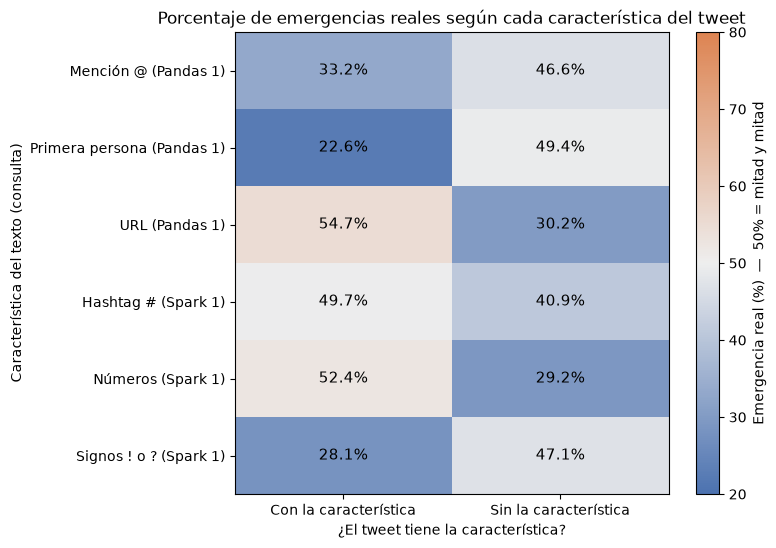

In [30]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# resultados de Pandas (consulta Pandas 1) y de Spark (consulta Spark 1)
tabla = pd.concat([
    resumen_texto["emergencia_real"].unstack().rename(index=lambda nombre: f"{nombre} (Pandas 1)"),
    pd.Series({clave: porcentaje for clave, (_, porcentaje) in emergencia_por_caracteristica.items()})
      .unstack().rename(index=lambda nombre: f"{nombre} (Spark 1)"),
]).reindex(columns=[True, False])  # columna "con" primero

# azul = mayoría figurado, gris = mitad y mitad, naranja = mayoría real
paleta = LinearSegmentedColormap.from_list("figurado_real", ["#4C72B0", "#EEEEEE", "#DD8452"])

fig, ax = plt.subplots(figsize=(7, 6))
imagen = ax.imshow(tabla, cmap=paleta, norm=TwoSlopeNorm(vmin=20, vcenter=50, vmax=80), aspect="auto")

for fila in range(tabla.shape[0]):
    for columna in range(tabla.shape[1]):
        ax.text(columna, fila, f"{tabla.iloc[fila, columna]:.1f}%", ha="center", va="center", fontsize=11)

ax.set_xticks([0, 1], ["Con la característica", "Sin la característica"])
ax.set_yticks(range(len(tabla)), tabla.index)
ax.set_xlabel("¿El tweet tiene la característica?")
ax.set_ylabel("Característica del texto (consulta)")
ax.set_title("Porcentaje de emergencias reales según cada característica del tweet")
fig.colorbar(imagen, ax=ax, label="Emergencia real (%)  —  50% = mitad y mitad")

plt.show()

El mapa permite comparar todas las señales de un vistazo:

- Las características que más empujan hacia el **lenguaje figurado** son la **primera persona** (22,6% de reales) y los **signos ! o ?** (28,1%), seguidas por las **menciones @** (33,2%).
- Las que más separan los grupos hacia la **emergencia real** son las **URL** (54,7% con, 30,2% sin) y los **números** (52,4% con, 29,2% sin). Aun así, los tweets que las tienen apenas superan la mitad.
- El **hashtag** es la señal más débil: con o sin él, el porcentaje queda cerca de la mitad.

En resumen, el texto tiene señales más fuertes para reconocer el lenguaje figurado que para confirmar una emergencia real.

# Conclusiones principales

El objetivo del dataset es detectar automáticamente si un tweet habla de una **emergencia real** o si usa palabras de desastre en **sentido figurado**. A partir del análisis exploratorio llegamos a las siguientes conclusiones:

**1. La keyword es la señal más fuerte.** Hay keywords que casi determinan el tipo de tweet: *debris*, *derailment* y *wreckage* son 100% emergencias reales, mientras que *aftershock* es 0%. Sin embargo, otras como *bombed* o *explosion* son totalmente ambiguas, así que la keyword por sí sola no alcanza (Pandas 3). Además, importa la forma de la palabra: dentro de una misma familia, *wreckage* es 100% real y *wrecked* solo 8% (Spark 5).

**2. El vocabulario del texto distingue los dos grupos, pero por pocas palabras.** Los tweets reales hablan de hechos y consecuencias (*fire*, *news*, *police*, *killed*) y los figurados, de la vida cotidiana del autor (*love*, *body*, *video*) (Pandas 4, Spark 2). Aun así, cerca del 75% de las palabras usadas pertenecen a un vocabulario común a los dos tipos; lo que distingue a un tweet real son unas pocas palabras de hechos concretos que casi nunca aparecen en sentido figurado (Spark 3).

**3. El lenguaje figurado se reconoce mejor que la emergencia real.** Las señales más fuertes apuntan hacia lo figurado:
- **Primera persona:** solo el 22,6% de los tweets que la usan son reales (Pandas 1).
- **Signos ! o ?:** 28,1% de reales (Spark 1).
- **Menciones @:** 33,2% de reales (Pandas 1).

En cambio, los tweets con señales de emergencia real (**URL** con 54,7% y **números** con 52,4%) apenas superan la mitad, aunque su ausencia sí baja mucho la proporción de reales (Pandas 1, Spark 1).

**4. Algunas características aportan poco.** El **largo** del tweet tiene una correlación de solo 0,18 con el tipo (Pandas 2) y su efecto cambia de signo según la keyword (Pandas 5); el **hashtag** deja los grupos casi mitad y mitad (Spark 1), y la **ubicación** no tiene relación con el tipo de tweet: con o sin ella, la proporción de reales es la misma (Pandas 6).

**5. El etiquetado tiene ruido.** Hay 18 textos idénticos etiquetados a la vez como emergencia real y como lenguaje figurado (Spark 4), lo que pone un límite a cualquier clasificación basada solo en el texto.

**En síntesis:** ninguna característica aislada alcanza para clasificar un tweet con seguridad. Pero varias señales débiles o moderadas apuntan en direcciones consistentes: un tweet impersonal, con URL, números y vocabulario de hechos concretos tiende a ser una emergencia real, mientras que uno en primera persona, con signos emocionales y menciones tiende a ser figurado.